<a href="https://colab.research.google.com/github/torusama/apriori-tid-mining/blob/main/notebooks/demo_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 02 — Apriori-TID Mining (Google Colab)
Chạy trên Colab bằng kernel Python; cell đầu chuẩn bị repository, Julia, Java và dependencies.


## 1. Cài đặt môi trường
Chuẩn bị Julia, Java và các thư viện cần thiết.

In [1]:
if not __import__("pathlib").Path("/content").is_dir():
    raise RuntimeError("Run demo_colab.ipynb on Google Colab; use demo_local.ipynb locally.")

import os
import shutil
import shlex
import re
import subprocess
import tempfile
from pathlib import Path
def download_runtime_archive(url, destination):
    subprocess.run(["curl", "-fLsS", "--retry", "2", "--max-time", "240",
                    url, "-o", str(destination)], check=True)
from IPython.display import Image, SVG, Markdown, display

# Peak RSS on Linux uses GNU time; it is absent on some fresh Colab runtimes.
if not Path("/usr/bin/time").is_file():
    print("Installing GNU time for peak RAM measurements...", flush=True)
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(["apt-get", "install", "-y", "-qq", "time"], check=True)


repository_url = "https://github.com/torusama/apriori-tid-mining.git"
repository_branch = "main"

repository = None
for directory in [Path.cwd(), *Path.cwd().parents]:
    if (directory / "scripts" / "visual_pipeline.jl").is_file():
        repository = directory
        break

if repository is None:
    repository = Path.cwd() / "apriori-tid-mining"
    uploaded_zip = Path("/content/apriori-tid-mining-reviewed.zip")
    if not uploaded_zip.is_file():
        uploaded_zip = Path("/content/apriori-tid-mining-ready.zip")
    if not uploaded_zip.is_file():
        uploaded_zip = Path("/content/apriori-tid-mining.zip")
    if uploaded_zip.is_file():
        subprocess.run(["unzip", "-o", str(uploaded_zip), "-d", str(Path.cwd())], check=True)
    elif not repository.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", repository_branch,
                        repository_url, str(repository)], check=True)

for required_file in ["demo.jl", "scripts/fetch_datasets.jl", "scripts/plot_results.jl",
                      "scripts/visual_pipeline.jl", "scripts/run_all_tests.jl"]:
    if not (repository / required_file).is_file():
        raise RuntimeError("The repository is missing the integrated files. Upload the ZIP or update the GitHub branch.")

julia = shutil.which("julia")
if julia is None:
    julia_version = "1.10.10"
    installation_directory = Path(tempfile.gettempdir()) / ("julia-" + julia_version)
    julia = str(installation_directory / "bin" / "julia")
    if not Path(julia).is_file():
        with tempfile.TemporaryDirectory() as download_directory:
            archive = Path(download_directory) / "julia.tar.gz"
            download_runtime_archive(f"https://julialang-s3.julialang.org/bin/linux/x64/1.10/julia-{julia_version}-linux-x86_64.tar.gz", archive)
            subprocess.run(["tar", "-xzf", str(archive), "-C", str(installation_directory.parent)], check=True)

# Cài Java 25 cho SPMF nếu cần.
def java_is_compatible():
    if shutil.which("java") is None:
        return False
    version = subprocess.run(["java", "-version"], capture_output=True, text=True, check=True)
    major = re.search(r'version "(\d+)', version.stderr + version.stdout)
    return major is not None and int(major.group(1)) >= 25

if not java_is_compatible():
    if not Path("/content").is_dir():
        raise RuntimeError("Install Java 25+ and add it to PATH before running this notebook locally.")
    java_directory = Path(tempfile.gettempdir()) / "apriori-openjdk25"
    java_directory.mkdir(parents=True, exist_ok=True)
    if not (java_directory / "bin/java").is_file():
        with tempfile.TemporaryDirectory() as download_directory:
            archive = Path(download_directory) / "java25.tar.gz"
            java_url = "https://download.java.net/java/GA/jdk25.0.2/b1e0dfa218384cb9959bdcb897162d4e/10/GPL/openjdk-25.0.2_linux-x64_bin.tar.gz"
            download_runtime_archive(java_url, archive)
            subprocess.run(["tar", "-xzf", str(archive), "-C", str(java_directory),
                            "--strip-components=1"], check=True)
    os.environ["JAVA_HOME"] = str(java_directory)
    os.environ["PATH"] = str(java_directory / "bin") + os.pathsep + os.environ["PATH"]

if not java_is_compatible():
    raise RuntimeError("SPMF needs Java 25 or newer.")
subprocess.run(["java", "-version"], check=True)

workspace = Path(tempfile.mkdtemp(prefix="apriori-demo-"))
raw_data = repository / "data" / "raw"

def run_julia(environment, script, *arguments, extra_environment=None, threads=None):
    command = [julia, "--startup-file=no"]
    if threads is not None:
        command.append(f"--threads={threads}")
    command.extend([f"--project={repository / environment}", str(repository / script)])
    for argument in arguments:
        command.append(str(argument))
    print(shlex.join(command), flush=True)
    subprocess.run(command, cwd=repository, check=True, env=extra_environment)

def instantiate(environment):
    subprocess.run([julia, "--startup-file=no", f"--project={repository / environment}",
                    "-e", "using Pkg; Pkg.instantiate()"], cwd=repository, check=True,
                   env=os.environ | {"JULIA_NUM_PRECOMPILE_TASKS": "2"})

print(subprocess.check_output([julia, "--version"], text=True).strip())
print("Repository:", repository)
instantiate(".")
instantiate("evaluation_environment")
instantiate("visual_environment")


Installing GNU time for peak RAM measurements...
julia version 1.12.6
Repository: /content/apriori-tid-mining


## 2. Kiểm tra Basic và Optimized
Chạy hai phiên bản với minsup 60% và so sánh kết quả.

In [2]:
for implementation in ("basic", "optimized"):
    run_julia(".", "demo.jl", "--minsup", "0.6", repository / "data/toy/sample.txt",
              "--output", workspace / f"{implementation}.txt", "--implementation", implementation)

basic_result = (workspace / "basic.txt").read_text()
assert basic_result == (workspace / "optimized.txt").read_text()
print(basic_result)


/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining /content/apriori-tid-mining/demo.jl --minsup 0.6 /content/apriori-tid-mining/data/toy/sample.txt --output /tmp/apriori-demo-b27um3_9/basic.txt --implementation basic
/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining /content/apriori-tid-mining/demo.jl --minsup 0.6 /content/apriori-tid-mining/data/toy/sample.txt --output /tmp/apriori-demo-b27um3_9/optimized.txt --implementation optimized
1 #SUP: 4
1 2 #SUP: 3
1 3 #SUP: 3
2 #SUP: 4
2 3 #SUP: 3
3 #SUP: 4



## 3. Kiểm thử
Chạy bộ test thuật toán, SPMF và xử lý ảnh.


In [3]:
run_julia(".", "test/runtests.jl")


/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining /content/apriori-tid-mining/test/runtests.jl


## 4. Tải dữ liệu benchmark
Tải và kiểm tra bốn bộ dữ liệu FIMI.


In [4]:
run_julia("evaluation_environment", "scripts/fetch_datasets.jl", "benchmark", "--root", raw_data)
benchmark_input_directory = raw_data / "benchmark"


/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining/evaluation_environment /content/apriori-tid-mining/scripts/fetch_datasets.jl benchmark --root /content/apriori-tid-mining/data/raw


### 4.1. So sánh với SPMF
So sánh itemset và support ở một mức minsup cho mỗi bộ dữ liệu.


In [5]:
benchmark_quick_cases = [
    ("chess", "0.96"),
    ("mushroom", "0.75"),
    ("retail", "0.05"),
    ("T10I4D100K", "0.045"),
]
spmf_jar = repository / "tools/spmf.jar"
for dataset_name, minimum_support in benchmark_quick_cases:
    print(f"\n{dataset_name}: minsup = {minimum_support}", flush=True)
    run_julia(".", "scripts/compare_spmf.jl", spmf_jar,
              benchmark_input_directory / f"{dataset_name}.txt", minimum_support, threads=1)



chess: minsup = 0.96
/usr/local/bin/julia --startup-file=no --threads=1 --project=/content/apriori-tid-mining /content/apriori-tid-mining/scripts/compare_spmf.jl /content/apriori-tid-mining/tools/spmf.jar /content/apriori-tid-mining/data/raw/benchmark/chess.txt 0.96

mushroom: minsup = 0.75
/usr/local/bin/julia --startup-file=no --threads=1 --project=/content/apriori-tid-mining /content/apriori-tid-mining/scripts/compare_spmf.jl /content/apriori-tid-mining/tools/spmf.jar /content/apriori-tid-mining/data/raw/benchmark/mushroom.txt 0.75

retail: minsup = 0.05
/usr/local/bin/julia --startup-file=no --threads=1 --project=/content/apriori-tid-mining /content/apriori-tid-mining/scripts/compare_spmf.jl /content/apriori-tid-mining/tools/spmf.jar /content/apriori-tid-mining/data/raw/benchmark/retail.txt 0.05

T10I4D100K: minsup = 0.045
/usr/local/bin/julia --startup-file=no --threads=1 --project=/content/apriori-tid-mining /content/apriori-tid-mining/scripts/compare_spmf.jl /content/apriori-ti

### 4.2. Chạy benchmark
Đo thời gian, bộ nhớ và khả năng mở rộng. Đặt `run_full_benchmark = False` để bỏ qua bước này.

/usr/local/bin/julia --startup-file=no --threads=1 --project=/content/apriori-tid-mining /content/apriori-tid-mining/scripts/run_benchmark.jl /content/apriori-tid-mining/data/raw/benchmark /tmp/apriori-demo-b27um3_9/benchmark_new /content/apriori-tid-mining/tools/spmf.jar /content/apriori-tid-mining/configs/benchmark.toml
/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining/evaluation_environment /content/apriori-tid-mining/scripts/plot_results.jl benchmark /tmp/apriori-demo-b27um3_9/benchmark_new
New benchmark results: /tmp/apriori-demo-b27um3_9/benchmark_new
Julia: 1.12.6
Julia threads: 1
OS and architecture: Linux x86_64
CPU: Intel(R) Xeon(R) CPU @ 2.20GHz
Host RAM bytes: 13605810176
SPMF SHA-256: 4aa468384693b2016b457ea310a08cc24aa83abd42d3169ad65b9027778dfe6a
Java: [0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,containe

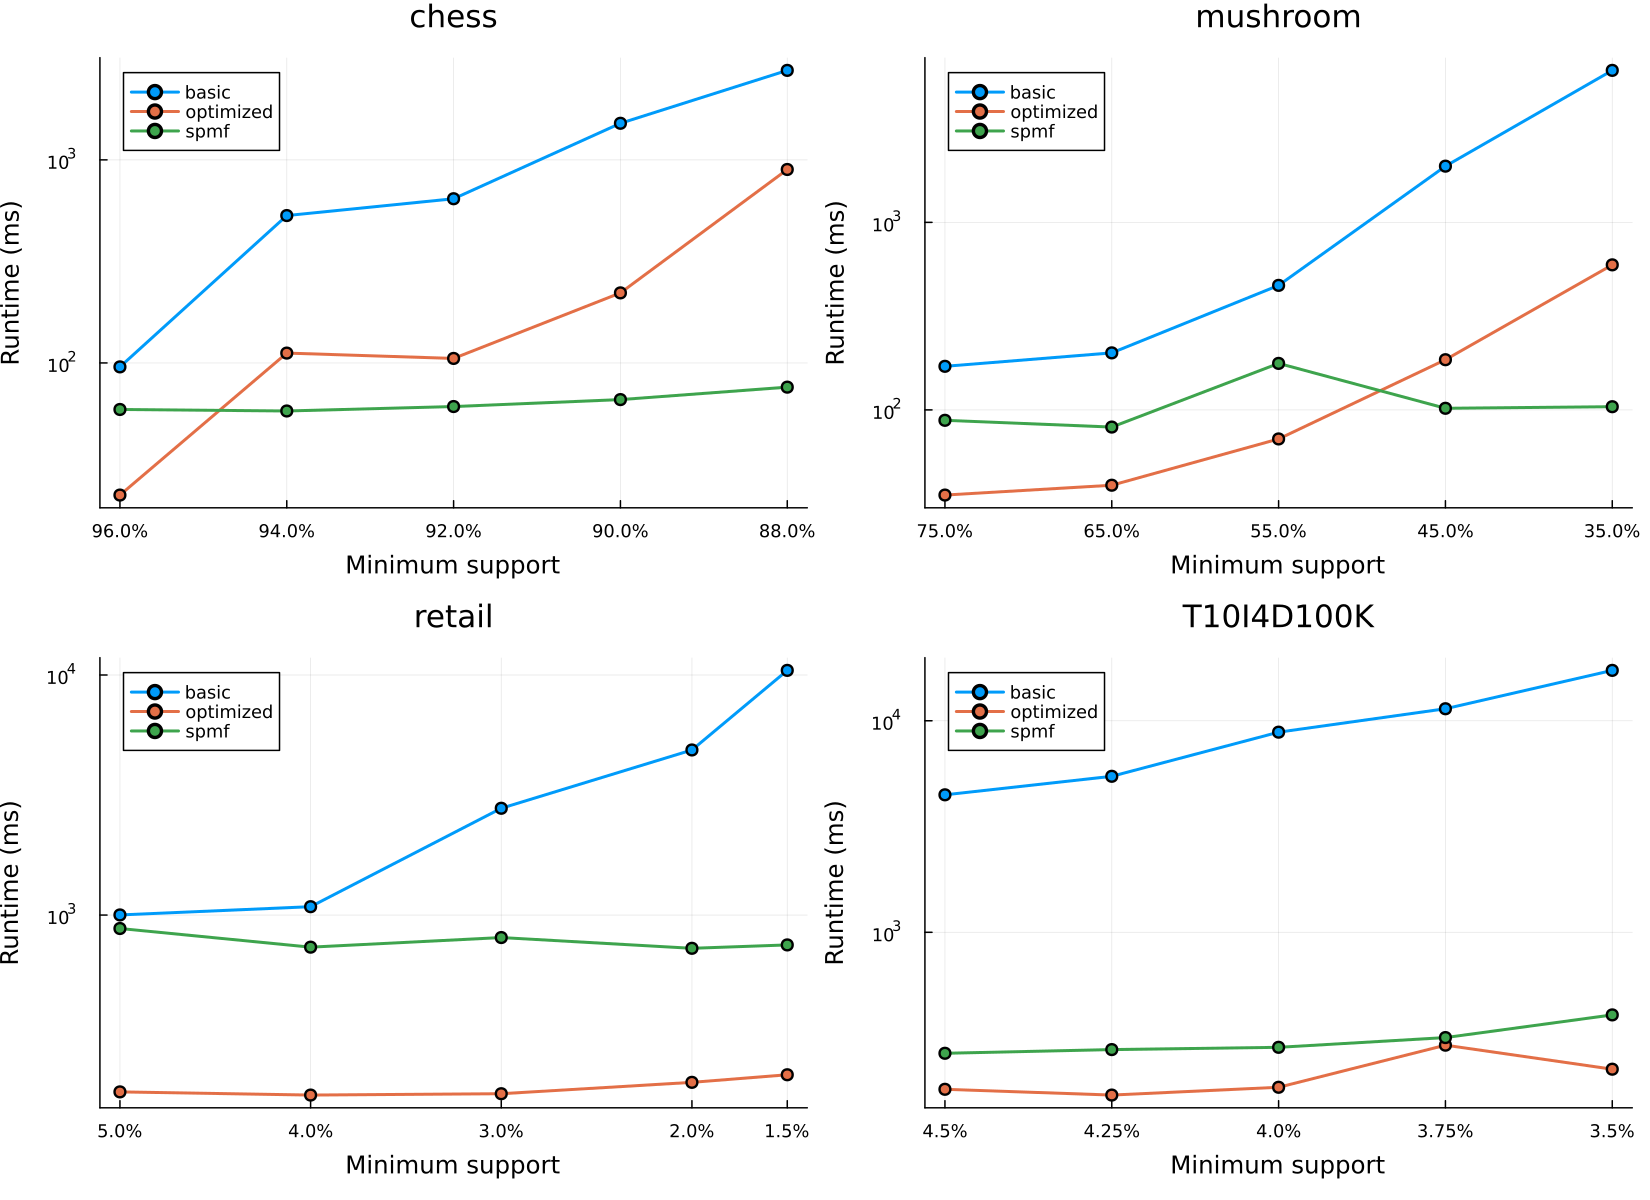

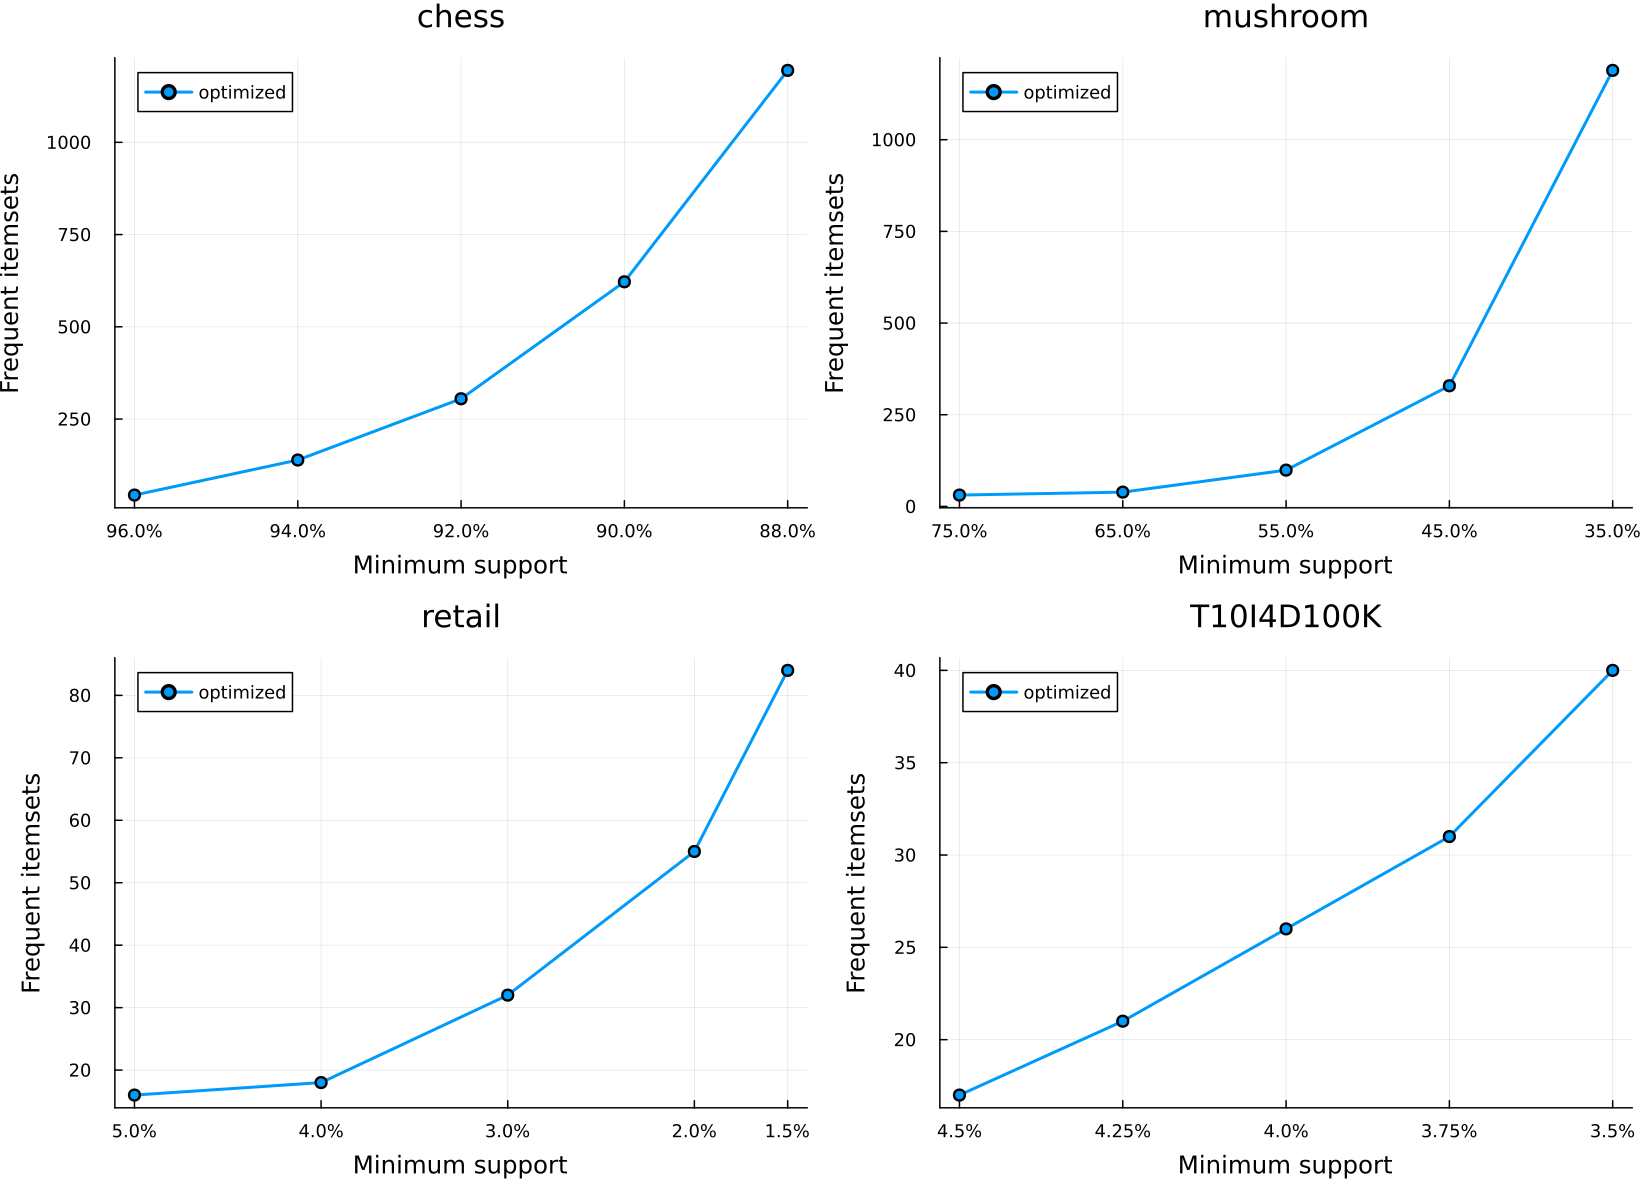

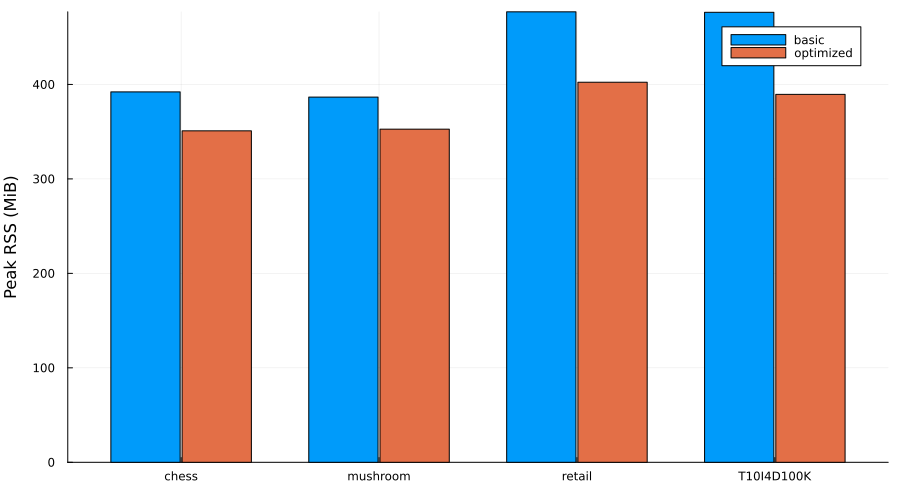

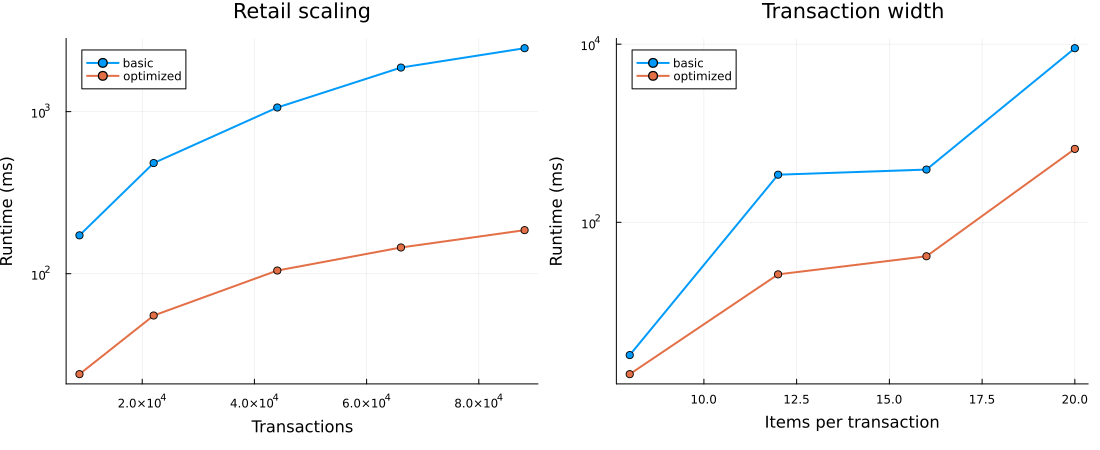

In [6]:
run_full_benchmark = True  #@param {type:"boolean"}
if run_full_benchmark:
    benchmark_directory = workspace / "benchmark_new"
    run_julia(".", "scripts/run_benchmark.jl", benchmark_input_directory,
              benchmark_directory, spmf_jar, repository / "configs/benchmark.toml", threads=1)
    run_julia("evaluation_environment", "scripts/plot_results.jl", "benchmark", benchmark_directory)
    print("New benchmark results:", benchmark_directory)
    print((benchmark_directory / "environment.txt").read_text())
    for filename in ("runtime_ms.png", "itemsets.png", "peak_ram.png", "scaling_and_width.png"):
        display(Image(filename=str(benchmark_directory / filename)))
else:
    print("Skipped full benchmark, set run_full_benchmark = True to run it.")


## 5. Ứng dụng 1 — Market Basket Analysis
Tạo luật kết hợp từ Groceries với minsup 1% và minconf 40%.

/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining/evaluation_environment /content/apriori-tid-mining/scripts/fetch_datasets.jl groceries --root /content/apriori-tid-mining/data/raw
/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining /content/apriori-tid-mining/scripts/run_market_basket.jl /content/apriori-tid-mining/data/raw/groceries/Groceries.data /content/apriori-tid-mining/data/raw/groceries/Groceries.labels /tmp/apriori-demo-b27um3_9/groceries 0.01 0.4 optimized
/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining/evaluation_environment /content/apriori-tid-mining/scripts/plot_results.jl groceries /tmp/apriori-demo-b27um3_9/groceries
antecedent,consequent,support_count,support,confidence,lift
"citrus fruit + root vegetables","other vegetables",102,0.010371123538383325,0.5862068965517241,3.0296084222733617
"root vegetables + tropical fruit","other vegetables",121,0.012302999491611592,0.5845410628019324,3.02

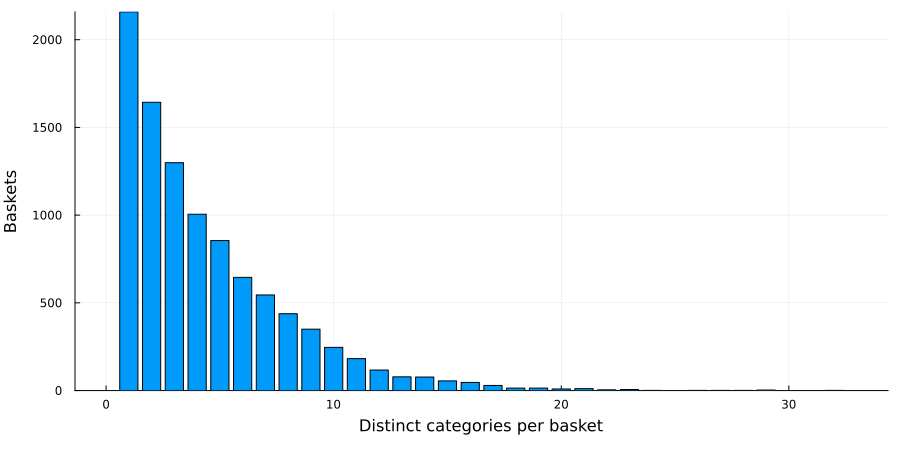

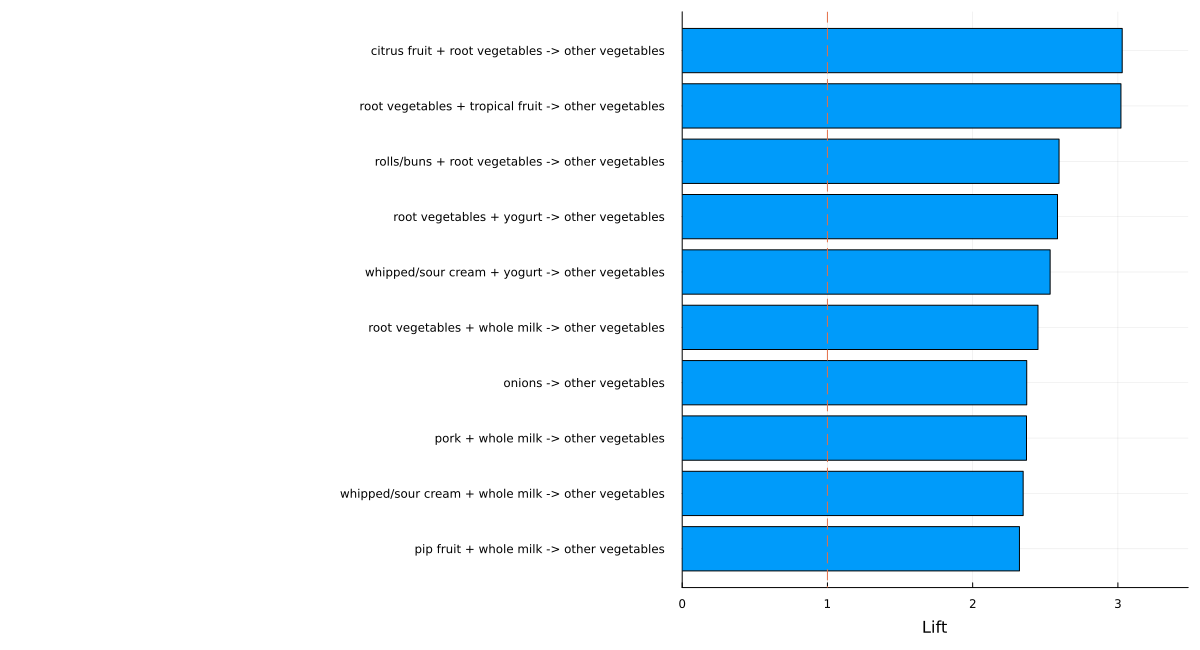

In [7]:
groceries_output = workspace / "groceries"
run_julia("evaluation_environment", "scripts/fetch_datasets.jl", "groceries", "--root", raw_data)
run_julia(".", "scripts/run_market_basket.jl", raw_data / "groceries/Groceries.data",
          raw_data / "groceries/Groceries.labels", groceries_output, "0.01", "0.4", "optimized")
run_julia("evaluation_environment", "scripts/plot_results.jl", "groceries", groceries_output)
print((groceries_output / "top10_rules.csv").read_text())
for filename in ("basket_lengths.png", "top10_rules.png"):
    display(Image(filename=str(groceries_output / filename)))

## 6. Ứng dụng 2 — Visual Pattern Mining
Chuyển ảnh Flowers-17 thành visual words và khai thác tập phổ biến.
Mặc định chạy toàn bộ ảnh, đổi `image_limit` để chạy thử ít ảnh hơn.

/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining/visual_environment /content/apriori-tid-mining/scripts/visual_pipeline.jl --output /tmp/apriori-demo-b27um3_9/flowers_k8 --limit 0 --words 8 --maximum-descriptors 100 --seed 42 --minsup 0.7,0.8,0.9
training_descriptors = 18815
saturated_images = 1077
julia_version = "1.12.6"
dataset_url = "https://www.robots.ox.ac.uk/~vgg/data/flowers/17/17flowers.tgz"
descriptor = "ORB (ImageFeatures.jl)"
archive_sha256 = "fe38a60f8b4a95e657551247d3e7d799a3fafcdbc595be504b12839967823d70"
run_utc = "2026-11-27T06:43:07.603"
clustering = "K-Means (Clustering.jl)"
total_descriptors = 122744
maximum_descriptors = 100
images = 1360
maximum_side = 256
seed = 42
visual_words = 8
empty_transactions = 2
valid_images = 1360

minimum_support,absolute_minimum_support,num_transactions,num_patterns,seconds,implementation
0.7,952,1360,255,3.565722096,optimized
0.8,1088,1360,250,0.044262088,optimized
0.9,1224,1360,47,0.010185222,optimized



# Visual Pattern Mining Analysis

Images and transactions: 1360.

- Minsup 0.7: 255 frequent itemsets.
- Minsup 0.8: 250 frequent itemsets.
- Minsup 0.9: 47 frequent itemsets.

Images containing all 8 visual words: 1077/1360 (79.19%).
Average visual words per image: 7.58.
High saturation can reduce the ability of patterns to distinguish images. Compare a larger K or fewer descriptors on the same images.
Each pattern can be used as a binary feature for classification or image retrieval. Evaluate on an independent test set before drawing conclusions.

ORB describes local image regions. Visual words are descriptor clusters, not necessarily specific flower parts.
Transactions discard spatial positions and repetitions. K, seed and image size affect results; co-occurrence does not establish classification performance.


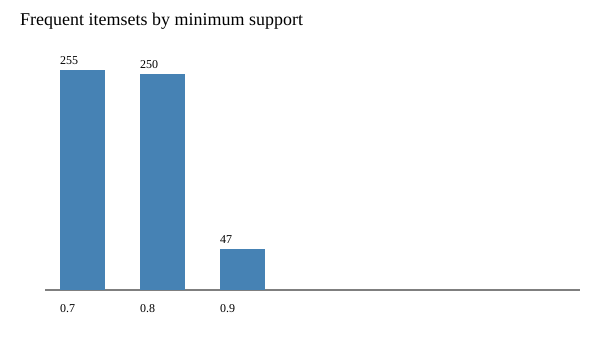

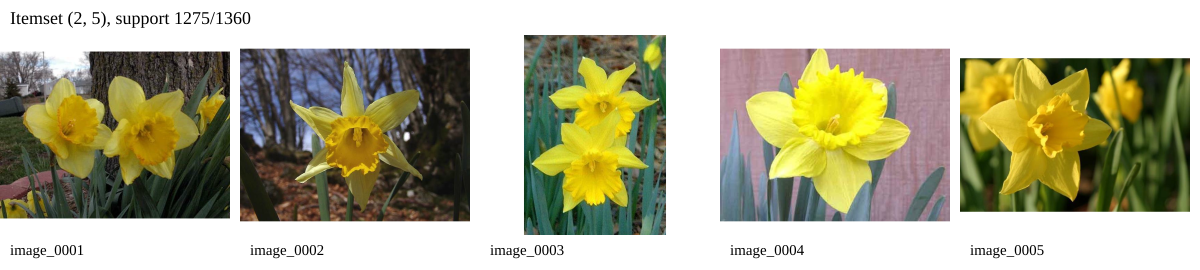

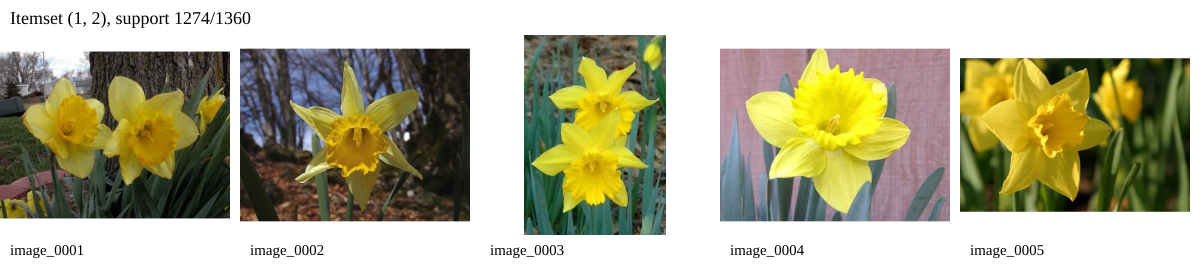

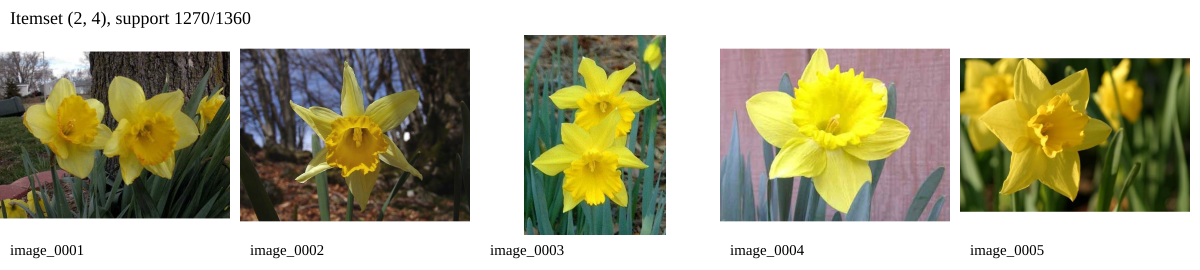

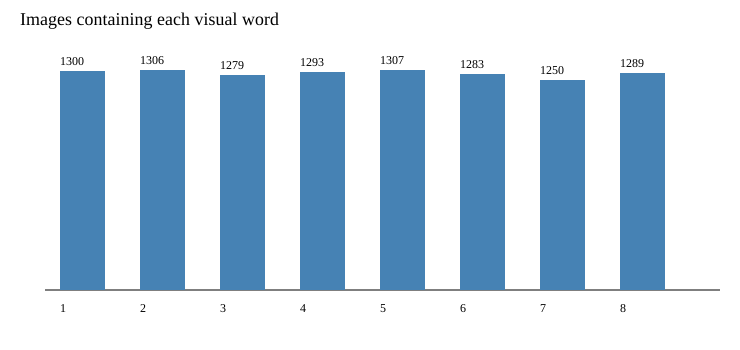

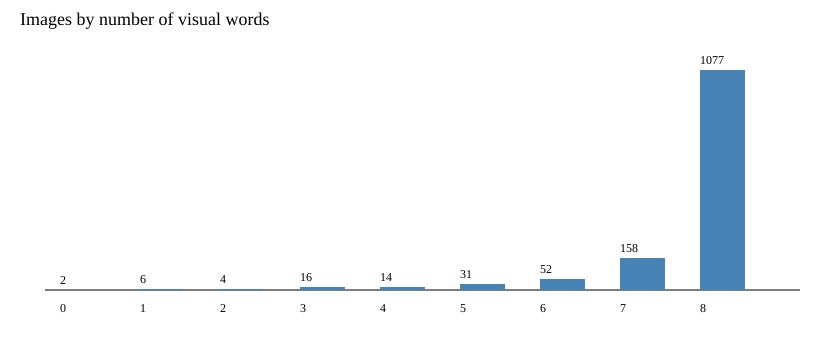

In [8]:
image_limit = 0
visual_words = 8
maximum_descriptors = 100
minimum_support_values = "0.7,0.8,0.9"
visual_output = workspace / "flowers_k8"

run_julia("visual_environment", "scripts/visual_pipeline.jl", "--output", visual_output,
          "--limit", image_limit, "--words", visual_words, "--maximum-descriptors", maximum_descriptors,
          "--seed", 42, "--minsup", minimum_support_values)
print((visual_output / "dataset_summary.toml").read_text())
print((visual_output / "runs.csv").read_text())
display(Markdown((visual_output / "analysis.md").read_text()))
for figure_path in sorted((visual_output / "figures").glob("*.svg")):
    display(SVG(filename=str(figure_path)))

## 7. Thử cấu hình ảnh khác
Chạy lại với 16 cụm và tối đa 40 descriptor mỗi ảnh.

/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining/visual_environment /content/apriori-tid-mining/scripts/visual_pipeline.jl --output /tmp/apriori-demo-b27um3_9/flowers_k16 --limit 0 --words 16 --maximum-descriptors 40 --seed 42 --minsup 0.7,0.8,0.9
training_descriptors = 18815
saturated_images = 8
julia_version = "1.12.6"
dataset_url = "https://www.robots.ox.ac.uk/~vgg/data/flowers/17/17flowers.tgz"
descriptor = "ORB (ImageFeatures.jl)"
archive_sha256 = "fe38a60f8b4a95e657551247d3e7d799a3fafcdbc595be504b12839967823d70"
run_utc = "2026-11-27T06:45:52.728"
clustering = "K-Means (Clustering.jl)"
total_descriptors = 52459
maximum_descriptors = 40
images = 1360
maximum_side = 256
seed = 42
visual_words = 16
empty_transactions = 2
valid_images = 1360

minimum_support,absolute_minimum_support,num_transactions,num_patterns,seconds,implementation
0.7,952,1360,11,0.184104568,optimized
0.8,1088,1360,0,0.00256069,optimized
0.9,1224,1360,0,0.002262459,optimized



# Visual Pattern Mining Analysis

Images and transactions: 1360.

- Minsup 0.7: 11 frequent itemsets.
- Minsup 0.8: 0 frequent itemsets.
- Minsup 0.9: 0 frequent itemsets.

Images containing all 16 visual words: 8/1360 (0.59%).
Average visual words per image: 11.38.
High saturation can reduce the ability of patterns to distinguish images. Compare a larger K or fewer descriptors on the same images.
Each pattern can be used as a binary feature for classification or image retrieval. Evaluate on an independent test set before drawing conclusions.

ORB describes local image regions. Visual words are descriptor clusters, not necessarily specific flower parts.
Transactions discard spatial positions and repetitions. K, seed and image size affect results; co-occurrence does not establish classification performance.


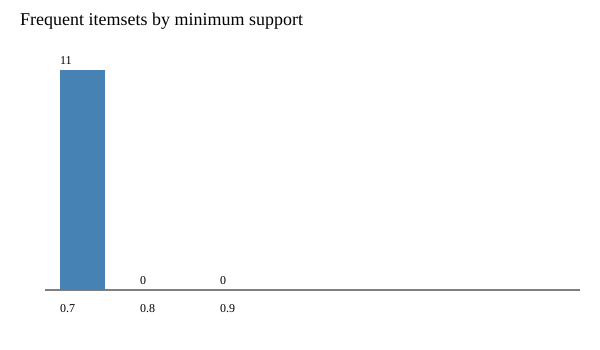

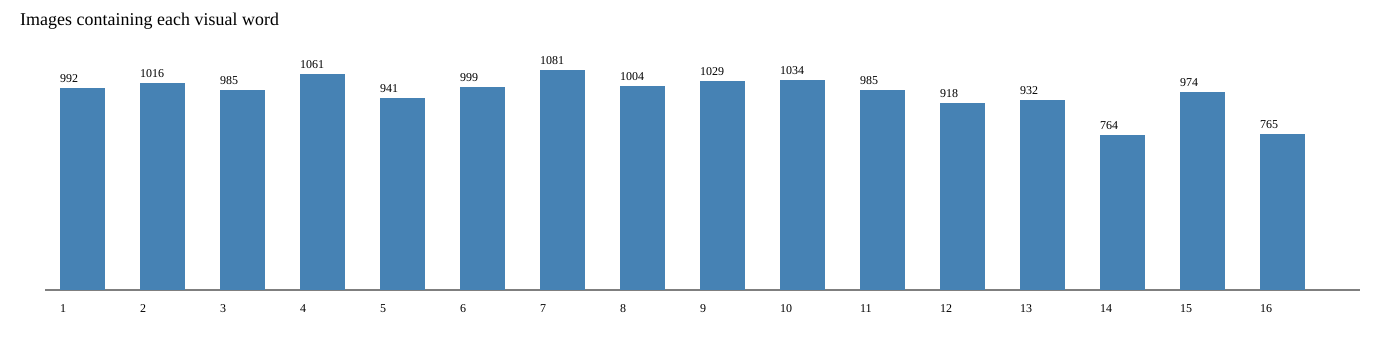

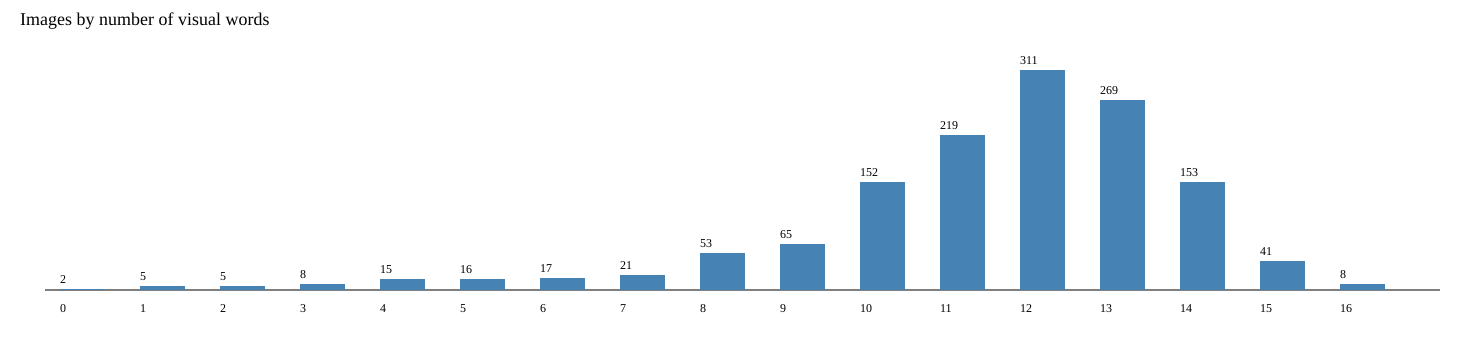

In [9]:
alternative_output = workspace / "flowers_k16"
run_julia("visual_environment", "scripts/visual_pipeline.jl", "--output", alternative_output,
          "--limit", image_limit, "--words", 16, "--maximum-descriptors", 40,
          "--seed", 42, "--minsup", minimum_support_values)
print((alternative_output / "dataset_summary.toml").read_text())
print((alternative_output / "runs.csv").read_text())
display(Markdown((alternative_output / "analysis.md").read_text()))
for figure_path in sorted((alternative_output / "figures").glob("*.svg")):
    display(SVG(filename=str(figure_path)))

## 8. Thư mục kết quả
Đường dẫn đến các kết quả vừa chạy.

In [10]:
print("Output directory:", workspace)

Output directory: /tmp/apriori-demo-b27um3_9
